# Data Exploration for Union Elections - Wins/Losses

this is the notebook file used for the Exploratory Data Analysis of the data scraped from NLRB.gov website of different cases. 

We will first go through the raw data looking at the different data types that the features use, and general information that can give us more information about the features before creating visualizations and making preliminary thoughts on what features should be focused on more. 

In [264]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


pd.set_option('display.width', 200)

MAIN = "#2ad6bc"        # main color
LIGHT = "#f58fa9"  # lighter step of the same blue, for ordered pairs (e.g. faster / slower)
CONTRAST = '#eb6834'      # contrast color (e.g. won vs lost) and reference lines
GRID = '#9a9a9a'        # grid lines


df = pd.read_csv("../data/elections_clean.csv")
display(df.head())
# column types and missing values
print(df.info())

,fiscal_year,case_number,case_name,employer,city,state,census_region,union_name,parent_union,eligible,...,n_participants,employer_has_lawyer,n_employer_lawyers,employer_law_firms,petitioner_has_lawyer,n_petitioner_lawyers,has_intervenor,petition_date,days_petition_to_election,union_won
0,2015,06-RC-012276,Point Park University,point park university,Pittsburgh,PA,Northeast,NEWSPAPER GUILD OF PITTSBURGH COMMUNICATIONS W...,CWA,67.0,...,8.0,1.0,1.0,"Jackson Lewis, P.C.",1.0,2.0,0.0,NaN,NaN,1
1,2012,09-RC-018160,COLUMBUS SOUTHERN POWER COMPANY,columbus southern power,Columbus,OH,Midwest,INTERNATIONAL BROTHERHOOD OF ELECTRICAL WORKER...,IBEW,33.0,...,3.0,1.0,1.0,Woods Rogers Vandeventer Black PLC,0.0,0.0,0.0,2007-08-06,38.0,0
2,2012,11-RC-006654,APPALACHIAN POWER COMPANY,appalachian power,Roanoke,VA,South,"LOCAL UNION 978, INTERNATIONAL BROTHERHOOD OF ...",IBEW,27.0,...,4.0,1.0,1.0,Woods Rogers PLC,0.0,0.0,0.0,2006-11-17,300.0,0
3,2014,05-RC-016210,"Interbake Foods, LLC",interbake foods,Front Royal,VA,South,"BAKERY, CONFECTIONERY, TOBACCO, WORKERS AND GR...",BCTGM,206.0,...,5.0,1.0,2.0,NELSON MULLINS RILEY & SCARBOROUGH LLP; Perkin...,1.0,1.0,0.0,NaN,NaN,0
4,2012,16-RC-010844,Plano Symphony Orchestra,plano symphony orchestra,Plano,TX,South,DALLAS/FORT WORTH PROFESSIONAL MUSICIANS ASSOC...,Other,108.0,...,6.0,1.0,2.0,Littler Mendelson P.C.,1.0,2.0,0.0,2008-04-24,146.0,0


<class 'pandas.DataFrame'>
RangeIndex: 15270 entries, 0 to 15269
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   fiscal_year                15270 non-null  int64  
 1   case_number                15270 non-null  str    
 2   case_name                  15270 non-null  str    
 3   employer                   15270 non-null  str    
 4   city                       15269 non-null  str    
 5   state                      15270 non-null  str    
 6   census_region              15270 non-null  str    
 7   union_name                 15270 non-null  str    
 8   parent_union               15270 non-null  str    
 9   eligible                   15113 non-null  float64
 10  election_date              15270 non-null  str    
 11  n_participants             15266 non-null  float64
 12  employer_has_lawyer        15266 non-null  float64
 13  n_employer_lawyers         15266 non-null  float64
 14  e

Examining election dates by year, where election date is day of the vote.

We scraped cases from fiscal years 2012-2026. 2012 starts from october 2011.
But earlier years showed because the cases had stayed open after the vote. 
The reports are grouped by when cases closed, so this makes sense.

In [265]:
df['election_date'] = pd.to_datetime(df['election_date'])
df['year'] = df['election_date'].dt.year
df['month'] = df['election_date'].dt.month   # 1 = January
print(df['year'].value_counts().sort_index())

year
2004       1
2007       2
2008       2
2009       3
2010       7
2011     387
2012    1121
2013    1144
2014    1148
2015    1302
2016    1086
2017    1124
2018     899
2019     915
2020     541
2021     642
2022    1175
2023     465
2024    1405
2025    1073
2026     828
Name: count, dtype: int64


In [266]:
df.dtypes.value_counts()

str               10
float64            8
int64              2
int32              2
datetime64[us]     1
Name: count, dtype: int64

In [267]:
df.nunique()

fiscal_year                     15
case_number                  15241
case_name                    11207
employer                      9471
city                          4060
state                           54
census_region                    5
union_name                    7983
parent_union                    34
eligible                       609
election_date                 3489
n_participants                  17
employer_has_lawyer              2
n_employer_lawyers               9
employer_law_firms            3553
petitioner_has_lawyer            2
n_petitioner_lawyers             7
has_intervenor                   2
petition_date                 3612
days_petition_to_election      375
union_won                        2
year                            21
month                           12
dtype: int64

In [268]:

df[['eligible', 'days_petition_to_election']]. describe()

,eligible,days_petition_to_election
count,15113.000000,14560.000000
mean,62.588037,42.940385
std,335.571288,91.701628
min,1.000000,2.000000
25%,10.000000,24.000000
50%,22.000000,31.000000
75%,53.000000,41.000000
max,35050.000000,3444.000000


It seems in most cases, both the employer and petitioner have lawyers.

The second most common is that employers have lawyers while the union doesn't.

In [269]:

df[['employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor']].value_counts()

employer_has_lawyer  petitioner_has_lawyer  has_intervenor
1.0                  1.0                    0.0               8167
                     0.0                    0.0               4926
0.0                  0.0                    0.0               1100
                     1.0                    0.0                646
1.0                  1.0                    1.0                207
                     0.0                    1.0                119
0.0                  0.0                    1.0                 61
                     1.0                    1.0                 40
Name: count, dtype: int64

In [270]:
df["census_region"].value_counts(normalize=True)

census_region
Northeast    0.291749
West         0.276424
Midwest      0.233595
South        0.184938
Territory    0.013294
Name: proportion, dtype: float64

## Now Looking at the Target Variable

Trying to look for information about the number of wins vs the number of losses to see how balanced the datat set is and if theres enough information to make a good prediction for this target variable. 

In [271]:
print(df['union_won'].value_counts())
print(df['union_won'].value_counts(normalize=True).round(3))

union_won
1    10813
0     4457
Name: count, dtype: int64
union_won
1    0.708
0    0.292
Name: proportion, dtype: float64


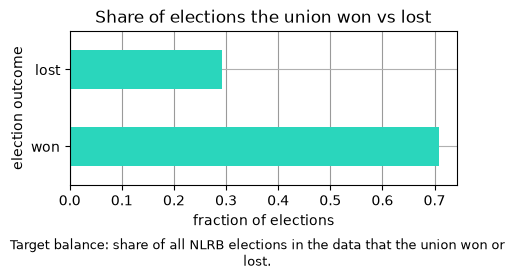

In [272]:
plt.figure(figsize=(5,2))
df['union_won'].map({1: 'won', 0: 'lost'}).value_counts(normalize=True).plot.barh(color=MAIN)
plt.xlabel('fraction of elections')
plt.ylabel('election outcome')
plt.title('Share of elections the union won vs lost')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.15, 'Target balance: share of all NLRB elections in the data that the union won or lost.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

## Looking at individual columns

going one by one looking at each feature in general, sometimes focusing on the relationship to wins. 

In [273]:
# days from petition to election 
print(df['days_petition_to_election'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

count    14560.000000
mean        42.940385
std         91.701628
min          2.000000
5%          16.000000
25%         24.000000
50%         31.000000
75%         41.000000
95%         79.000000
99%        299.410000
max       3444.000000
Name: days_petition_to_election, dtype: float64


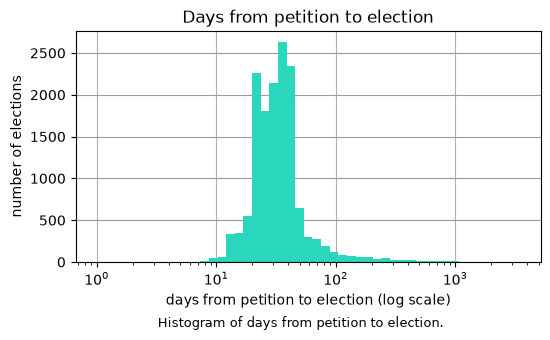

In [274]:
# long right tail, so log-spaced bins like the capital-gain example in lecture 4
days = df['days_petition_to_election'].dropna()

plt.figure(figsize=(6,3))
days.plot.hist(bins=np.logspace(np.log10(1), np.log10(days.max()), 50), color=MAIN)
plt.semilogx()
plt.xlabel('days from petition to election (log scale)')
plt.ylabel('number of elections')
plt.title('Days from petition to election')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.07, 'Histogram of days from petition to election.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

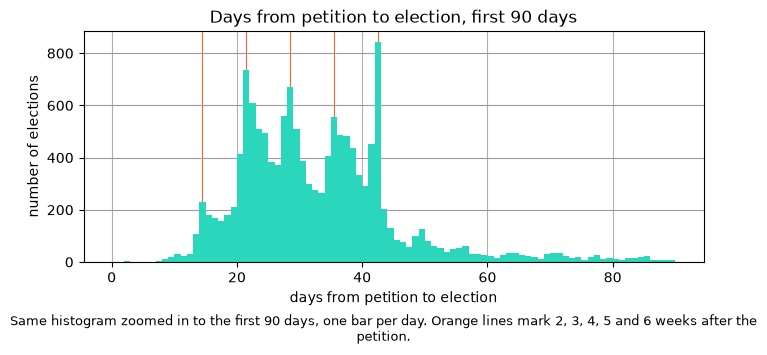

In [275]:
# zoom in on the first 90 days, one bar per day
plt.figure(figsize=(8,3))
days.plot.hist(bins=np.arange(0, 91), color=MAIN)
for week in [14, 21, 28, 35, 42]:
    plt.axvline(week + 0.5, color=CONTRAST, linewidth=0.8, zorder=0)
plt.xlabel('days from petition to election')
plt.ylabel('number of elections')
plt.title('Days from petition to election, first 90 days')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.06, 'Same histogram zoomed in to the first 90 days, one bar per day. Orange lines mark 2, 3, 4, 5 and 6 weeks after the petition.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()


looking at size of eligible voters

count    15113.000000
mean        62.588037
std        335.571288
min          1.000000
10%          5.000000
25%         10.000000
50%         22.000000
75%         53.000000
90%        126.800000
99%        598.880000
max      35050.000000
Name: eligible, dtype: float64


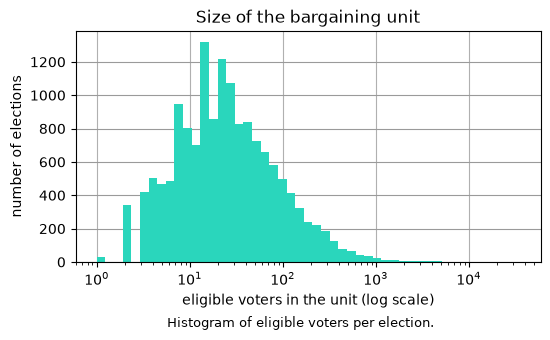

In [276]:
print(df['eligible'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

eligible = df['eligible'].dropna()
plt.figure(figsize=(6,3))
eligible.plot.hist(bins=np.logspace(0, np.log10(eligible.max()), 50), color=MAIN)
plt.semilogx()
plt.xlabel('eligible voters in the unit (log scale)')
plt.ylabel('number of elections')
plt.title('Size of the bargaining unit')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.07, 'Histogram of eligible voters per election.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

Looking at Ordinal + yes/no features (ones that relate to lawyer/another party participating)

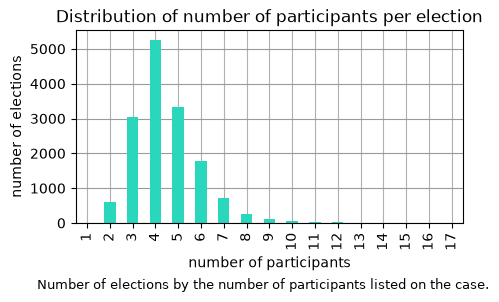

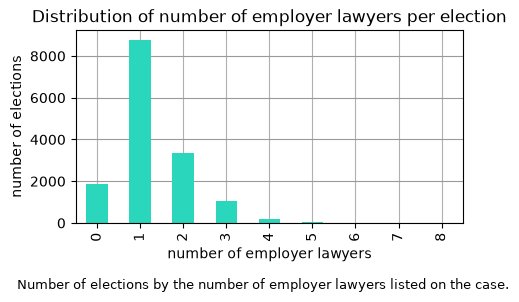

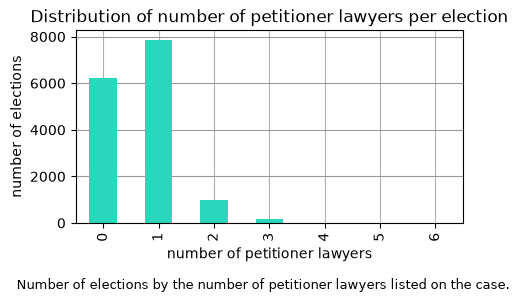

employer_has_lawyer
1.0    0.879
0.0    0.121
Name: proportion, dtype: float64 

petitioner_has_lawyer
1.0    0.593
0.0    0.407
Name: proportion, dtype: float64 

has_intervenor
0.0    0.972
1.0    0.028
Name: proportion, dtype: float64 



In [277]:
# Looking at features for if a column has lawyers/how many (ordinal + yes/no features)
nice_names = {'n_participants': 'number of participants',
              'n_employer_lawyers': 'number of employer lawyers',
              'n_petitioner_lawyers': 'number of petitioner lawyers'}
for col in ['n_participants', 'n_employer_lawyers', 'n_petitioner_lawyers']:
    plt.figure(figsize=(5,2.5))
    df[col].dropna().astype(int).value_counts().sort_index().plot.bar(color=MAIN)   # sort_index keeps the counts in order
    plt.xlabel(nice_names[col])
    plt.ylabel('number of elections')
    plt.title(f'Distribution of {nice_names[col]} per election')
    plt.grid(axis='y', color=GRID)
    plt.gca().set_axisbelow(True)   # grid behind the bars
    plt.figtext(0.5, -0.11, f'Number of elections by the {nice_names[col]} listed on the case.', ha='center', va='top', fontsize=9, wrap=True)
    plt.show()

for col in ['employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor']:
    print(df[col].value_counts(normalize=True).round(3), '\n')

Unions

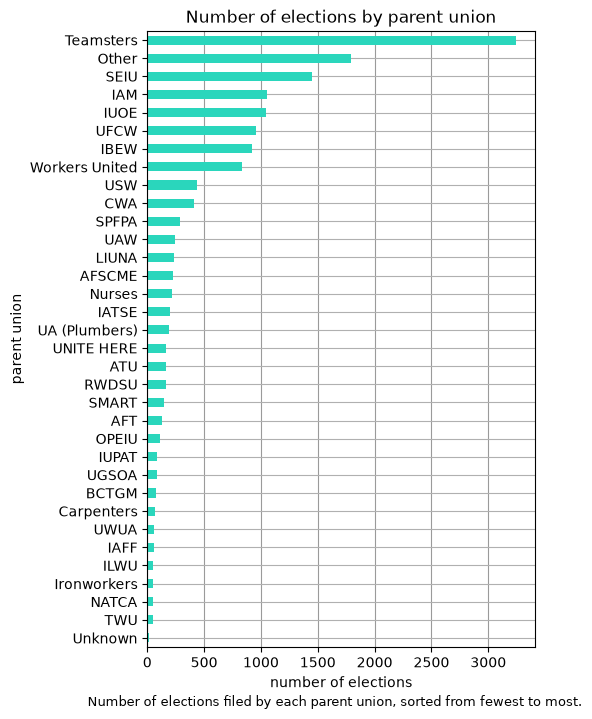

In [278]:
plt.figure(figsize=(5,8))
df['parent_union'].value_counts().sort_values().plot.barh(color=MAIN)
plt.xlabel('number of elections')
plt.ylabel('parent union')
plt.title('Number of elections by parent union')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, 0.05, 'Number of elections filed by each parent union, sorted from fewest to most.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

Regions + states 

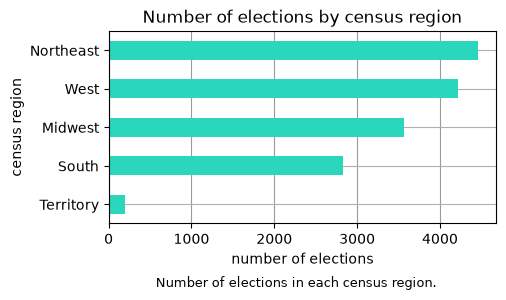

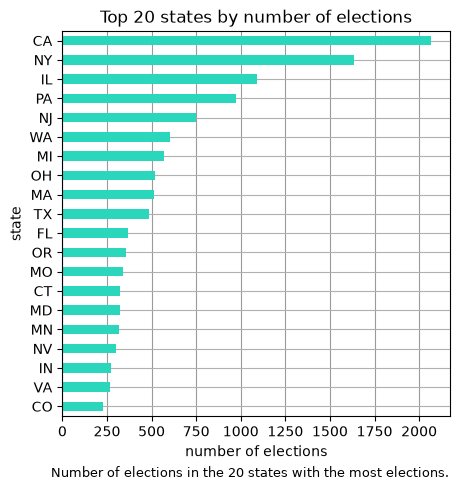

states/territories: 54


In [279]:
plt.figure(figsize=(5,2.5))
df['census_region'].value_counts().sort_values().plot.barh(color=MAIN)
plt.xlabel('number of elections')
plt.ylabel('census region')
plt.title('Number of elections by census region')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.1, 'Number of elections in each census region.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

plt.figure(figsize=(5,5))
df['state'].value_counts().head(20).sort_values().plot.barh(color=MAIN)
plt.xlabel('number of elections')
plt.ylabel('state')
plt.title('Top 20 states by number of elections')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, 0.01, 'Number of elections in the 20 states with the most elections.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

print('states/territories:', df['state'].nunique())

The employers and law firms a part of each case

In [280]:
print(df['employer'].value_counts().head(10))
print('\nStarbucks share of all elections:', round(df['employer'].str.contains('starbucks').mean(), 3))

employer
starbucks                      725
first student                  156
first transit                   77
asplundh tree expert            75
healthcare services group       65
mv transportation               58
cbre                            51
jones lang lasalle americas     43
durham school services          40
transdev services               40
Name: count, dtype: int64

Starbucks share of all elections: 0.047


unique firm names: 2818
unique keywords: 1495
keyword
littler      2256
jackson      1061
ogletree     1007
fisher        428
seyfarth      364
morgan        326
bond          198
davis         161
fox           156
baker         142
barnes        129
constangy     129
ford          124
law           120
cozen         111
Name: count, dtype: int64


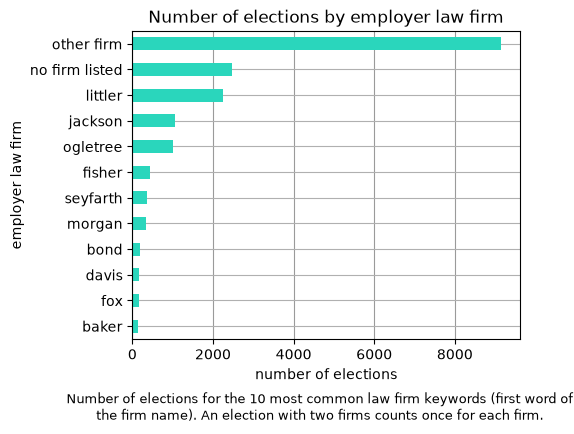

In [281]:
# one row per (election, law firm); an election with two firms shows up twice
firm_rows = df[['union_won', 'employer_law_firms']].copy()
firm_rows['firm'] = firm_rows['employer_law_firms'].str.lower().str.split('; ')
firm_rows = firm_rows.explode('firm', ignore_index=True)
# print(firm_rows['firm'].value_counts().head(12))

# the same firm is spelled several ways ("littler mendelson, p.c." / "littler mendelson pc"),
# so use the first word of the name as its keyword (skipping a leading "the")
firm_rows['keyword'] = firm_rows['firm'].str.replace(r'^the ', '', regex=True).str.extract(r'^(\w+)')[0]
print('unique firm names:', firm_rows['firm'].nunique())
print('unique keywords:', firm_rows['keyword'].nunique())
print(firm_rows['keyword'].value_counts().head(15))

# keep the 10 most common keywords as their own group, everything else is 'other firm'
top_keywords = firm_rows['keyword'].value_counts().head(10).index
firm_rows['firm_group'] = firm_rows['keyword'].where(firm_rows['keyword'].isin(top_keywords), 'other firm')
firm_rows.loc[firm_rows['firm'].isna(), 'firm_group'] = 'no firm listed'

plt.figure(figsize=(5,4))
firm_rows['firm_group'].value_counts().sort_values().plot.barh(color=MAIN)
plt.xlabel('number of elections')
plt.ylabel('employer law firm')
plt.title('Number of elections by employer law firm')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.02, 'Number of elections for the 10 most common law firm keywords (first word of the firm name). An election with two firms counts once for each firm.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

#### Trends across time : number of elections over time

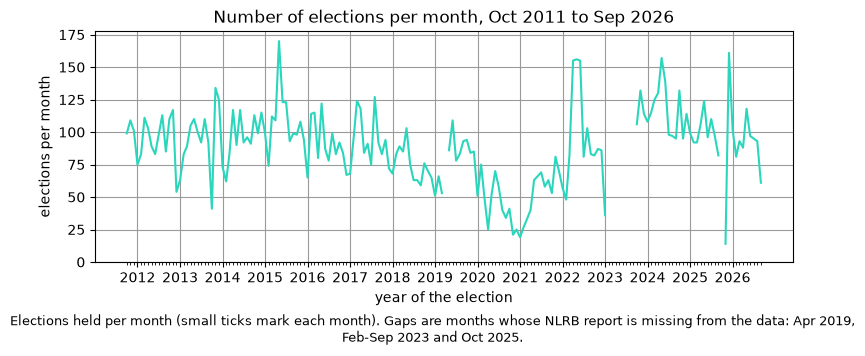

In [282]:
per_month = df.groupby(df['election_date'].dt.to_period('M')).size()
# a month with no elections has no row at all, so add every month back in as missing (NaN)
# so the line has a gap there instead of dropping to 0
per_month = per_month.reindex(pd.period_range('2011-10', '2026-09', freq='M'))

# months whose NLRB report is missing from the data (image-only PDFs we skipped, and the empty Oct 2025 shutdown report). Their counts are too low
# because of the missing report, not a real drop, so show them as gaps too
missing_reports = pd.period_range('2023-02', '2023-09', freq='M').append(pd.PeriodIndex(['2019-04', '2025-10'], freq='M'))
per_month[missing_reports] = np.nan
per_month.index = per_month.index.to_timestamp()

plt.figure(figsize=(9,3))
plt.plot(per_month.index, per_month.values, color=MAIN)
# a small tick for every month, and a label at every January
januaries = per_month.index[per_month.index.month == 1]
plt.xticks(januaries, januaries.strftime('%Y'))
plt.xticks(per_month.index, minor=True)
plt.xlabel('year of the election')
plt.ylabel('elections per month')
plt.ylim(bottom=0)
plt.title('Number of elections per month, Oct 2011 to Sep 2026')
plt.grid(color=GRID)
plt.figtext(0.5, -0.06, 'Elections held per month (small ticks mark each month). Gaps are months whose NLRB report is missing from the data: Apr 2019, Feb-Sep 2023 and Oct 2025.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

## Specific features vs the target variable

#### Days between petition and election

share of elections within 100 days: 0.965


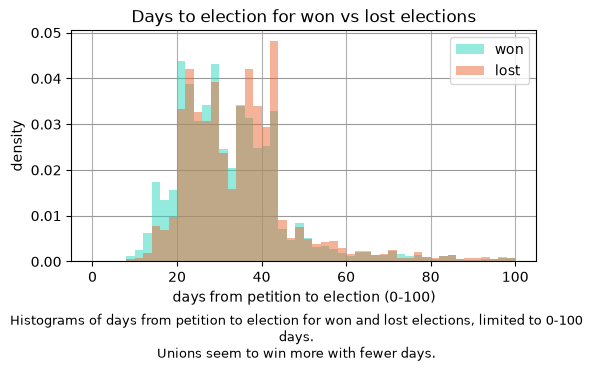

           mean  size
days_bin             
0–2       0.862   458
2–4       0.742  5643
4–6       0.686  6018
6–8       0.671  1178
8–10      0.679   364
10–12     0.715   242
> 12      0.577   657


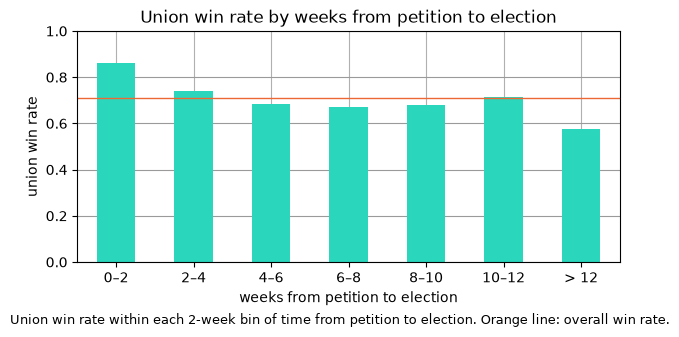

In [283]:
# category-specific histograms, zoomed to 0-100 days where almost all elections are
won = df[df['union_won'] == 1]['days_petition_to_election'].dropna()
lost = df[df['union_won'] == 0]['days_petition_to_election'].dropna()
print('share of elections within 100 days:', round((days <= 100).mean(), 3))

plt.figure(figsize=(6,3))
plt.hist(won, bins=50, range=(0, 100), density=True, alpha=0.5, color=MAIN, label='won')
plt.hist(lost, bins=50, range=(0, 100), density=True, alpha=0.5, color=CONTRAST, label='lost')
plt.legend()
plt.xlabel('days from petition to election (0-100)')
plt.ylabel('density')
plt.title('Days to election for won vs lost elections')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.06, 'Histograms of days from petition to election for won and lost elections, limited to 0-100 days.\nUnions seem to win more with fewer days.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

# win rate per bin of weeks: equal bins of 2 weeks up to 12 weeks, longer waits (about 5%) in one '> 12' bin
week_bins = list(range(0, 13, 2)) + [600]
week_labels = [f'{lower}–{lower + 2}' for lower in range(0, 12, 2)] + ['> 12']
df['days_bin'] = pd.cut(df['days_petition_to_election'] / 7, week_bins, labels=week_labels)
days_table = df.groupby('days_bin', observed=True)['union_won'].agg(['mean', 'size'])
print(days_table.round(3))

plt.figure(figsize=(7,3))
days_table['mean'].plot.bar(color=MAIN, rot=0)
plt.axhline(df['union_won'].mean(), color=CONTRAST, linewidth=1)
plt.ylim(0, 1)
plt.xlabel('weeks from petition to election')
plt.ylabel('union win rate')
plt.title('Union win rate by weeks from petition to election')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.06, 'Union win rate within each 2-week bin of time from petition to election. Orange line: overall win rate.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

#### The Size (eligible voters)

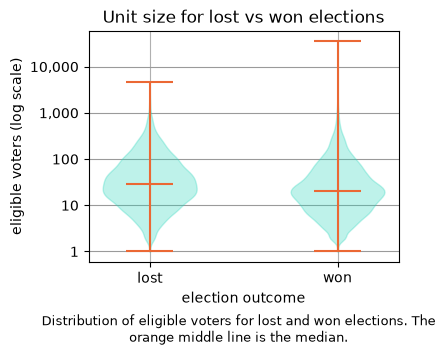

           mean  size
size_bin             
1–25      0.754  8320
26–50     0.676  2839
51–75     0.651  1228
76–100    0.637   730
101–125   0.629   469
126–150   0.611   298
151–175   0.597   221
176–200   0.570   135
201–225   0.641   153
226–250   0.586    99
251–275   0.580    88
276–300   0.642    81
301–325   0.698    53
326–350   0.641    39
351–375   0.634    41
376–400   0.514    35
401–425   0.583    24
426–450   0.650    20
451–475   0.857    14
476–500   0.536    28
> 500     0.652   198


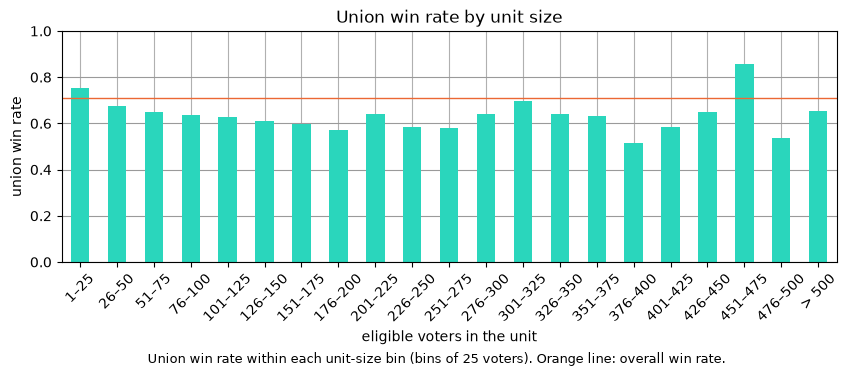

In [284]:
# violin plot instead of a box plot: thousands of outlier dots piled on top of each other.
# the shape is smoothed on the axis it's drawn on, so draw log10(size) and label the ticks in voters
lost_sizes = np.log10(df.loc[df['union_won'] == 0, 'eligible'].dropna())
won_sizes = np.log10(df.loc[df['union_won'] == 1, 'eligible'].dropna())

plt.figure(figsize=(4,3))
parts = plt.violinplot([lost_sizes, won_sizes], showmedians=True)
for body in parts['bodies']:
    body.set_color(MAIN)
for lines in ['cmins', 'cmaxes', 'cbars', 'cmedians']:   # min, max, whisker and median lines
    parts[lines].set_color(CONTRAST)
plt.xticks([1, 2], ['lost', 'won'])
plt.yticks([0, 1, 2, 3, 4], ['1', '10', '100', '1,000', '10,000'])
plt.title('Unit size for lost vs won elections')
plt.xlabel('election outcome')
plt.ylabel('eligible voters (log scale)')
plt.grid(axis='y', color=GRID)
plt.figtext(0.5, -0.06, 'Distribution of eligible voters for lost and won elections. The orange middle line is the median.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

# equal bins of 25 voters up to 500; the few bigger units (about 1%) go in one '> 500' bin
bin_width = 25
size_bins = list(range(0, 501, bin_width)) + [40000]
# label each bin from its lower edge, e.g. lower = 25 gives '26–50'
size_labels = [f'{lower + 1}–{lower + bin_width}' for lower in range(0, 500, bin_width)] + ['> 500']
df['size_bin'] = pd.cut(df['eligible'], size_bins, labels=size_labels)
size_table = df.groupby('size_bin', observed=True)['union_won'].agg(['mean', 'size'])
print(size_table.round(3))

plt.figure(figsize=(10,3))
size_table['mean'].plot.bar(color=MAIN, rot=45)
plt.axhline(df['union_won'].mean(), color=CONTRAST, linewidth=1)
plt.ylim(0, 1)
plt.xlabel('eligible voters in the unit')
plt.ylabel('union win rate')
plt.title('Union win rate by unit size')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.19, 'Union win rate within each unit-size bin (bins of 25 voters). Orange line: overall win rate.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

It appears that smaller units have higher win rates initially, but there are some peaks such as 451-475

#### Which Lawyer feature (ordinal features) have the most impact

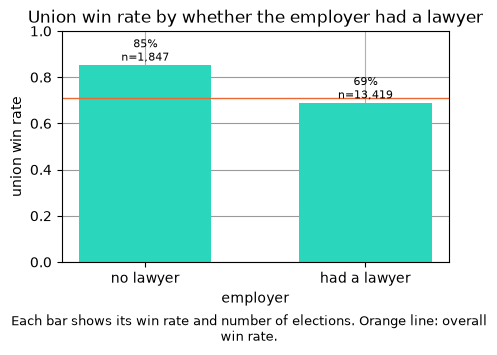

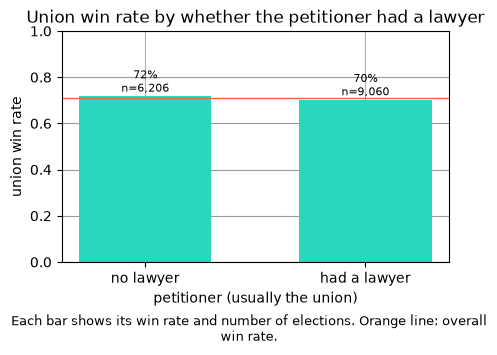

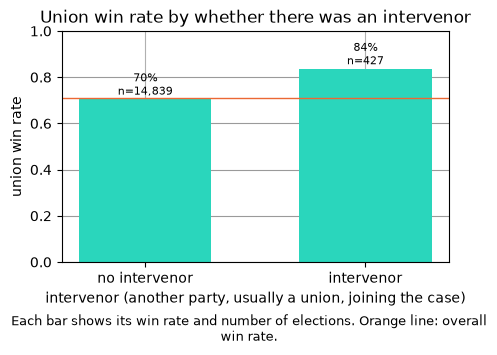

                                            mean  size
employer_has_lawyer petitioner_has_lawyer             
0.0                 0.0                    0.850  1161
                    1.0                    0.854   686
1.0                 0.0                    0.687  5045
                    1.0                    0.689  8374


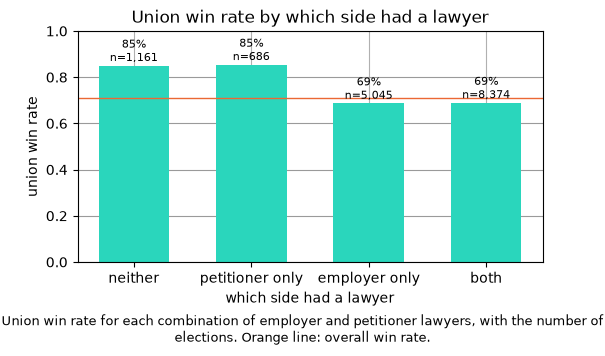

In [285]:
overall = df['union_won'].mean()

# one simple bar chart for each yes/no feature: (column, title, x label, bar labels for 0 and 1)
yes_no_plots = [('employer_has_lawyer', 'Union win rate by whether the employer had a lawyer',
                 'employer', ['no lawyer', 'had a lawyer']),
                ('petitioner_has_lawyer', 'Union win rate by whether the petitioner had a lawyer',
                 'petitioner (usually the union)', ['no lawyer', 'had a lawyer']),
                ('has_intervenor', 'Union win rate by whether there was an intervenor',
                 'intervenor (another party, usually a union, joining the case)', ['no intervenor', 'intervenor'])]

for col, title, xlabel, labels in yes_no_plots:
    table = df.groupby(col)['union_won'].agg(['mean', 'size'])   # rows are 0.0 then 1.0
    plt.figure(figsize=(5,3))
    plt.bar(labels, table['mean'], color=MAIN, width=0.6)
    for i, (rate, n) in enumerate(zip(table['mean'], table['size'])):
        plt.text(i, rate + 0.02, f'{rate:.0%}\nn={n:,}', ha='center', fontsize=8)
    plt.axhline(overall, color=CONTRAST, linewidth=1)
    plt.ylim(0, 1)
    plt.xlabel(xlabel)
    plt.ylabel('union win rate')
    plt.title(title)
    plt.grid(axis='y', color=GRID)
    plt.gca().set_axisbelow(True)   # grid behind the bars
    plt.figtext(0.5, -0.06, 'Each bar shows its win rate and number of elections. Orange line: overall win rate.', ha='center', va='top', fontsize=9, wrap=True)
    plt.show()

# every combination of employer lawyer and petitioner lawyer
combo = df.groupby(['employer_has_lawyer', 'petitioner_has_lawyer'])['union_won'].agg(['mean', 'size'])
print(combo.round(3))
combo_names = {(0.0, 0.0): 'neither', (0.0, 1.0): 'petitioner only',
               (1.0, 0.0): 'employer only', (1.0, 1.0): 'both'}
combo_labels = [combo_names[key] for key in combo.index]

plt.figure(figsize=(6,3))
plt.bar(combo_labels, combo['mean'], color=MAIN, width=0.6)
for i, (rate, n) in enumerate(zip(combo['mean'], combo['size'])):
    plt.text(i, rate + 0.02, f'{rate:.0%}\nn={n:,}', ha='center', fontsize=8)
plt.axhline(overall, color=CONTRAST, linewidth=1)
plt.ylim(0, 1)
plt.xlabel('which side had a lawyer')
plt.ylabel('union win rate')
plt.title('Union win rate by which side had a lawyer')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.06, 'Union win rate for each combination of employer and petitioner lawyers, with the number of elections. Orange line: overall win rate.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

It seems that when the employer has a lawyer and the union doesn't, it is at a disadvantage. So it does impact the win rate.
When the employer has a lawyer, the win rate goes down, so it has more power than if neither side had lawyers.


#### Parent Union vs. Number of Wins

                 mean  size
parent_union               
Unknown         0.000    11
BCTGM           0.473    74
Carpenters      0.485    66
UA (Plumbers)   0.503   193
SMART           0.517   143
USW             0.584   438
IUPAT           0.605    86
UFCW            0.623   955
Ironworkers     0.627    51
Teamsters       0.634  3247
IBEW            0.634   925
RWDSU           0.660   162
LIUNA           0.691   233
UAW             0.691   246
Other           0.703  1796
ATU             0.707   164
UNITE HERE      0.732   164
UWUA            0.746    59
IAM             0.751  1050
SPFPA           0.759   290
OPEIU           0.774   115
IUOE            0.778  1042
IAFF            0.800    55
AFSCME          0.802   222
SEIU            0.811  1450
TWU             0.820    50
Workers United  0.821   834
IATSE           0.825   200
UGSOA           0.837    86
CWA             0.841   409
ILWU            0.846    52
Nurses          0.882   221
AFT             0.892   130
NATCA           0.92

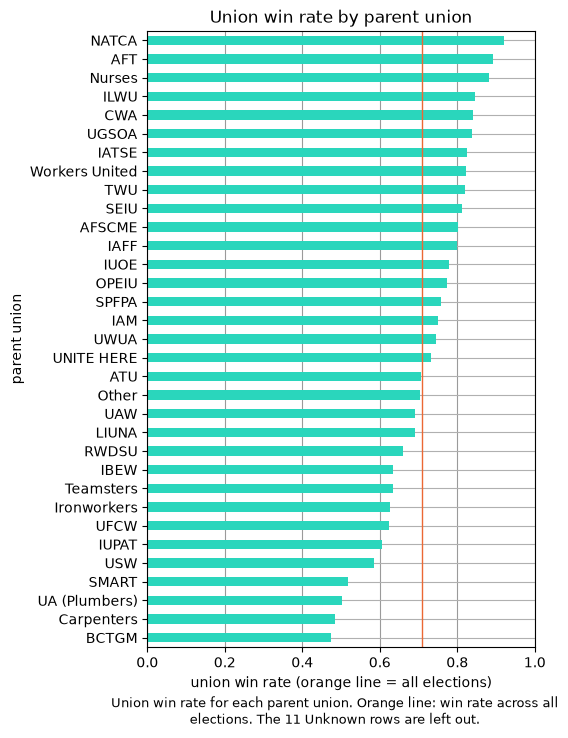

In [286]:
union_table = df.groupby('parent_union')['union_won'].agg(['mean', 'size']).sort_values('mean')
print(union_table.round(3))

# "Unknown" is the 11 rows where the PDF prints "** Data Incomplete **" instead of a union name
union_table = union_table.drop('Unknown')

plt.figure(figsize=(5,8))
union_table['mean'].plot.barh(color=MAIN)
plt.axvline(df['union_won'].mean(), color=CONTRAST, linewidth=1)
plt.xlim(0, 1)
plt.xlabel('union win rate (orange line = all elections)')
plt.ylabel('parent union')
plt.title('Union win rate by parent union')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, 0.05, 'Union win rate for each parent union. Orange line: win rate across all elections. The 11 Unknown rows are left out.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

#### Regions/where vs. number of wins

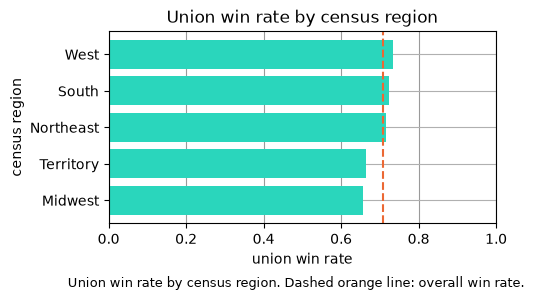

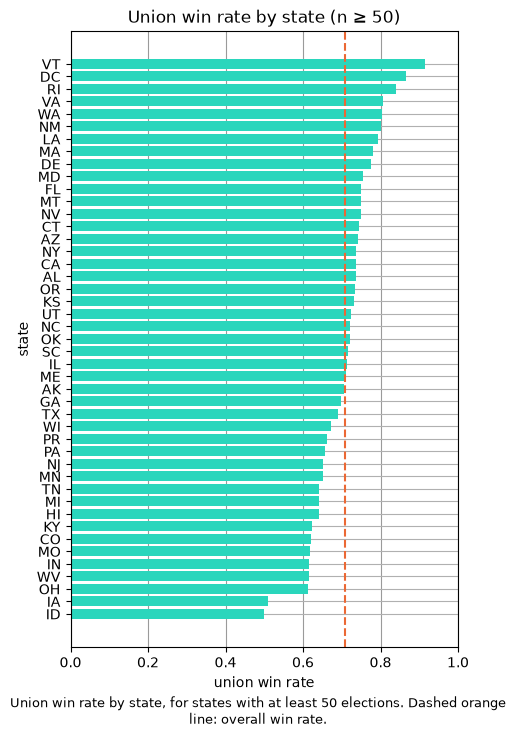

In [287]:
reg = df.groupby('census_region')['union_won'].mean().sort_values()

plt.figure(figsize=(5,2.5))
plt.barh(reg.index, reg.values, color=MAIN)
plt.axvline(df['union_won'].mean(), color=CONTRAST, linestyle='--')
plt.xlim(0, 1)
plt.xlabel('union win rate')
plt.ylabel('census region')
plt.title('Union win rate by census region')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.1, 'Union win rate by census region. Dashed orange line: overall win rate.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

st = df.groupby('state')['union_won'].agg(['mean', 'size'])
st = st[st['size'] >= 50].sort_values('mean')   # skip tiny states

plt.figure(figsize=(5,8))
plt.barh(st.index, st['mean'], color=MAIN)
plt.axvline(df['union_won'].mean(), color=CONTRAST, linestyle='--')
plt.xlim(0, 1)
plt.xlabel('union win rate')
plt.ylabel('state')
plt.title('Union win rate by state (n ≥ 50)')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, 0.05, 'Union win rate by state, for states with at least 50 elections. Dashed orange line: overall win rate.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

#### The employers law firm 

                 mean  size
firm_group                 
ogletree        0.576  1007
baker           0.592   142
jackson         0.624  1061
fisher          0.633   428
bond            0.677   198
fox             0.679   156
seyfarth        0.681   364
morgan          0.684   326
other firm      0.695  9155
davis           0.720   161
littler         0.741  2256
no firm listed  0.815  2478


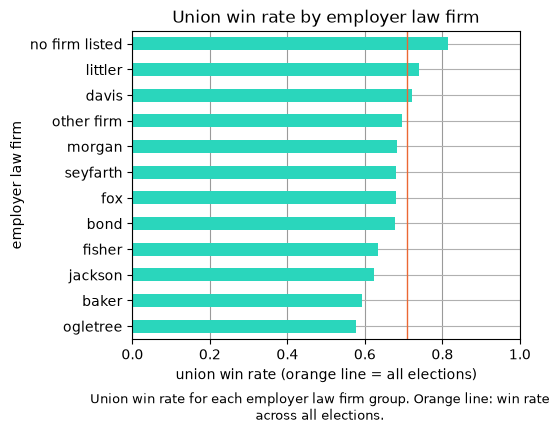

In [288]:
firm_table = firm_rows.groupby('firm_group')['union_won'].agg(['mean', 'size']).sort_values('mean')
print(firm_table.round(3))

plt.figure(figsize=(5,4))
firm_table['mean'].plot.barh(color=MAIN)
plt.axvline(df['union_won'].mean(), color=CONTRAST, linewidth=1)
plt.xlim(0, 1)
plt.xlabel('union win rate (orange line = all elections)')
plt.ylabel('employer law firm')
plt.title('Union win rate by employer law firm')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.02, 'Union win rate for each employer law firm group. Orange line: win rate across all elections.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

#### Time of year

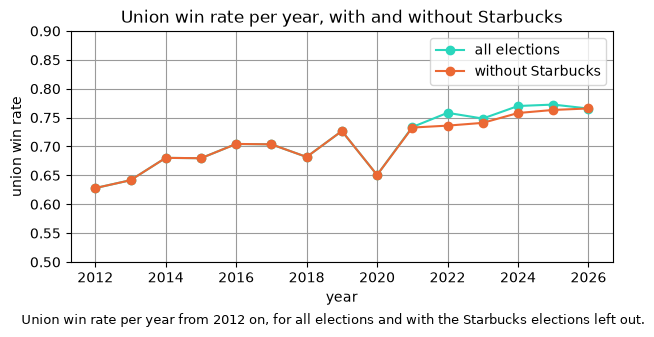

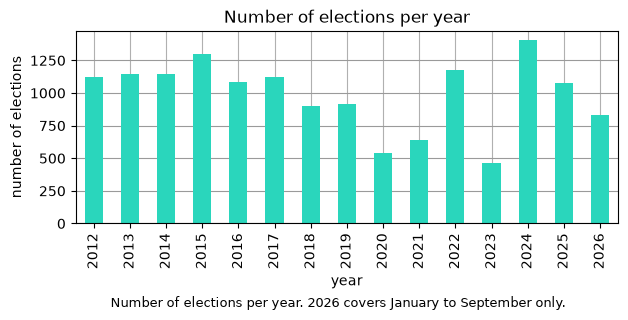

In [289]:
recent = df[df['year'] >= 2012]
by_year = recent.groupby('year')['union_won'].mean()
by_year_no_starbucks = recent[~recent['employer'].str.contains('starbucks')].groupby('year')['union_won'].mean()

plt.figure(figsize=(7,3))
plt.plot(by_year.index, by_year.values, marker='o', color=MAIN, label='all elections')
plt.plot(by_year_no_starbucks.index, by_year_no_starbucks.values, marker='o', color=CONTRAST, label='without Starbucks')
plt.ylim(0.5, 0.9)
plt.xlabel('year')
plt.ylabel('union win rate')
plt.title('Union win rate per year, with and without Starbucks')
plt.legend()
plt.grid(color=GRID)
plt.figtext(0.5, -0.06, 'Union win rate per year from 2012 on, for all elections and with the Starbucks elections left out.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

plt.figure(figsize=(7,2.5))
recent['year'].value_counts().sort_index().plot.bar(color=MAIN)
plt.xlabel('year')
plt.ylabel('number of elections')
plt.title('Number of elections per year')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, -0.18, 'Number of elections per year. 2026 covers January to September only.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

It appears that the union win rate is rising with the passage of time.
The lower win rates might be attributed to the lower number of elections and the pandemic.
Starbucks was checked as it is the employer with the share of many election cases.

## Are any features correlated?

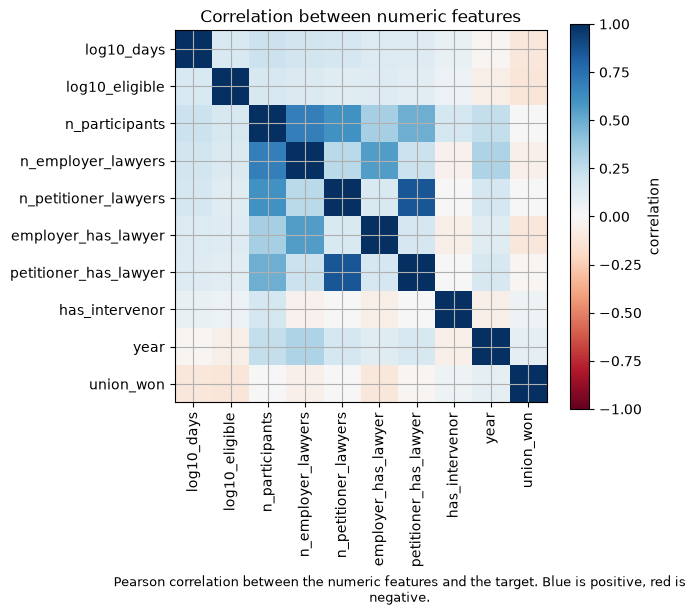

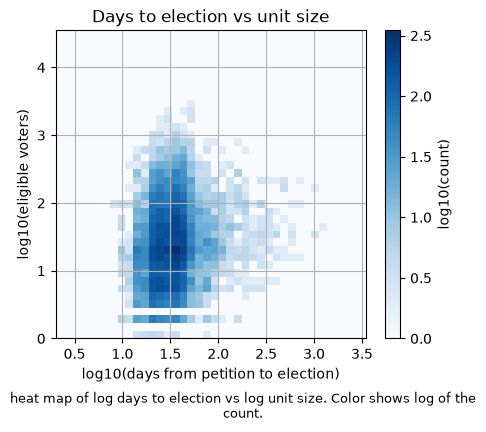

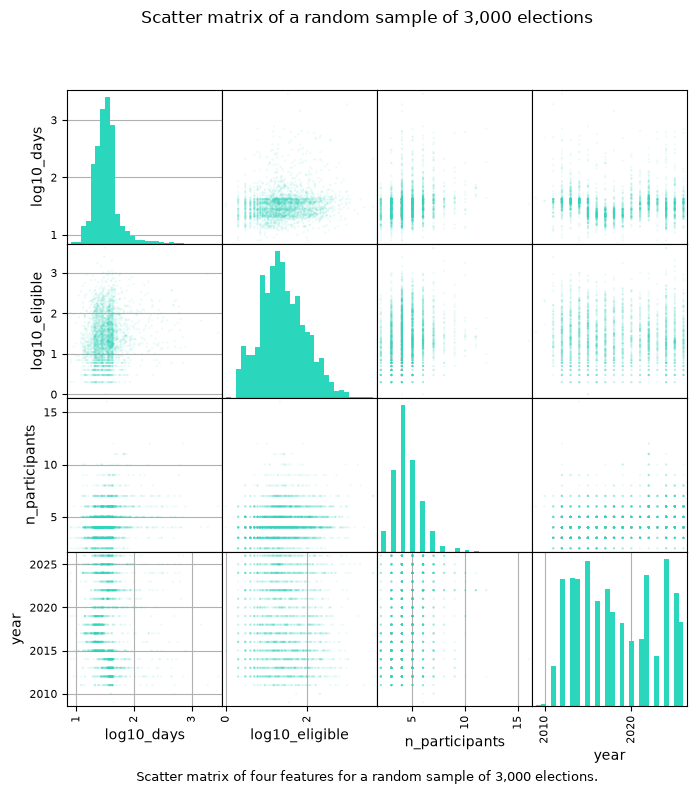

In [290]:
df['log10_days'] = np.log10(df['days_petition_to_election'])
df['log10_eligible'] = np.log10(df['eligible'])

numeric_cols = ['log10_days', 'log10_eligible', 'n_participants', 'n_employer_lawyers', 'n_petitioner_lawyers',
                'employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor', 'year', 'union_won']
corr = df[numeric_cols].corr()

plt.figure(figsize=(6,5))
plt.imshow(corr, cmap='RdBu', vmin=-1, vmax=1)   # blue = positive, red = negative, white = 0
plt.colorbar(label='correlation')
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=90)
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.title('Correlation between numeric features')
plt.figtext(0.5, -0.22, 'Pearson correlation between the numeric features and the target. Blue is positive, red is negative.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

# heatmap of two continuous columns on log scales
pair = df[['log10_days', 'log10_eligible']].dropna()
heatmap, xedges, yedges = np.histogram2d(pair['log10_days'], pair['log10_eligible'], bins=40)
heatmap[heatmap == 0] = 0.1   # we take the log and log(0) is undefined

plt.figure(figsize=(5,4))
plt.imshow(np.log10(heatmap).T, origin='lower', vmin=0, cmap='Blues', aspect='auto',
           extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])
plt.colorbar(label='log10(count)')
plt.xlabel('log10(days from petition to election)')
plt.ylabel('log10(eligible voters)')
plt.title('Days to election vs unit size')
plt.figtext(0.5, -0.02, 'heat map of log days to election vs log unit size. Color shows log of the count.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

sample = df[['log10_days', 'log10_eligible', 'n_participants', 'year']].dropna().sample(3000, random_state=1)
pd.plotting.scatter_matrix(sample, figsize=(8,8), alpha=0.1, s=10, color=MAIN, hist_kwds={'bins': 30, 'color': MAIN})
plt.suptitle('Scatter matrix of a random sample of 3,000 elections')
plt.figtext(0.5, 0.03, 'Scatter matrix of four features for a random sample of 3,000 elections.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()




It seems that there is no strong correlation between features

## Which features matter the most?

checking correlation and spread.
For each feature, will check the gap/disparity in win rates.

petitioner has lawyer           0.016
election month                  0.045
census region (5 groups)        0.077
has intervenor                  0.132
employer has lawyer             0.163
days to election (7 bins)       0.286
number of petitioner lawyers    0.302
unit size (21 bins)             0.343
state                           0.452
number of employer lawyers      0.500
parent union (34 groups)        0.922
number of participants          1.000
eligible                        1.000
election year                   1.000
dtype: float64


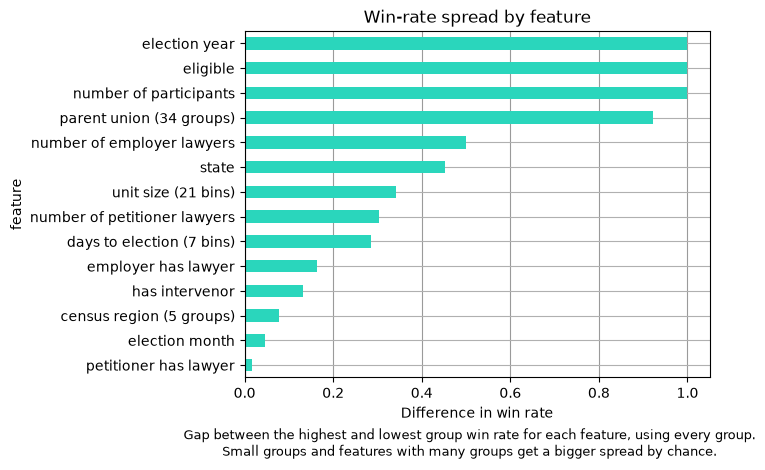

In [291]:
# for each feature: find the win rate of each group, then take highest minus lowest
features = {'days to election (7 bins)': 'days_bin',
            'unit size (21 bins)': 'size_bin',
            'employer has lawyer': 'employer_has_lawyer',
            'petitioner has lawyer': 'petitioner_has_lawyer',
            'has intervenor': 'has_intervenor',
            'number of participants': 'n_participants',
            'eligible': 'eligible',
            'number of employer lawyers': 'n_employer_lawyers',
            'number of petitioner lawyers': 'n_petitioner_lawyers',
            'parent union (34 groups)': 'parent_union',
            'census region (5 groups)': 'census_region',
            'state': 'state',
            'election year': 'year',
            'election month': 'month'}

spread = {}
for name, col in features.items():
    groups = df.groupby(col, observed=True)['union_won'].mean() #ignore win rates for missing values
    spread[name] = groups.max() - groups.min()

spread = pd.Series(spread).sort_values()
print(spread.round(3))

plt.figure(figsize=(6,4.5))
spread.plot.barh(color=MAIN)
plt.xlabel('Difference in win rate')
plt.ylabel('feature')
plt.title('Win-rate spread by feature')
plt.grid(axis='x', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.figtext(0.5, 0.0, 'Gap between the highest and lowest group win rate for each feature, using every group. Small groups and features with many groups get a bigger spread by chance.', ha='center', va='top', fontsize=9, wrap=True)
plt.show()

We will not take election year into account as win rates are increasing over the years.
We are interested in the difference unit size (eligible) makes,
the parent union, 
the existence of lawyers,
and days to election as people tend to assume that the smaller the days between petition and election date, the higher change of success for the union.

## Final Exploratory Visualizations

### Union win rate over time
finding a trend that unions win more now than in previous years

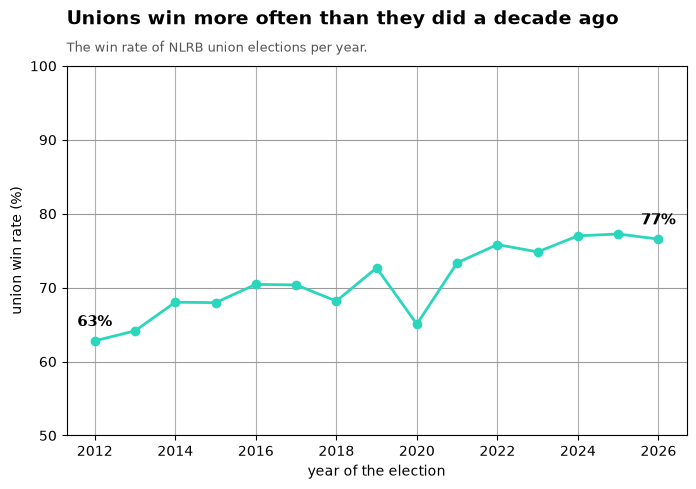

In [292]:
win_by_year = recent.groupby('year')['union_won'].mean() * 100

plt.figure(figsize=(8,4.8))
plt.plot(win_by_year.index, win_by_year.values, color=MAIN, linewidth=2, marker='o')
for year in [2012, 2026]:   # label the two ends only
    plt.text(year, win_by_year[year] + 2, f'{win_by_year[year]:.0f}%', ha='center', fontsize=11, fontweight='bold')
plt.ylim(50, 100)
plt.xticks(range(2012, 2027, 2))
plt.grid(axis='y', color=GRID)
plt.ylabel('union win rate (%)')
plt.xlabel('year of the election')
# bold headline (the message) and a gray subtitle (what is plotted) above the plot
plt.title('Unions win more often than they did a decade ago', loc='left', fontsize=14, fontweight='bold', pad=30)
plt.text(0, 1.03, 'The win rate of NLRB union elections per year.',
         transform=plt.gca().transAxes, fontsize=9.5, color='#555555', va='bottom')
plt.savefig('../figures/eda_1_win_rate_by_year.png', dpi=300, bbox_inches='tight')
plt.show()

### Union win rate over days to election
The longer the wait time is between petition and election, the more likely it is to lose the election

the win rate falls from 86% when the vote is within 2 weeks to about 67-69% at 4-10 weeks, and is lowest (58%) when the wait is over 12 weeks. Between 6 and 12 weeks it doesn't keep falling (10-12 weeks is 71%, but that bar is only 242 elections), so the drop is mostly in the first 6 weeks and after 12 weeks.

               mean  size
wait                     
0–2\nweeks    0.862   458
2–4\nweeks    0.742  5643
4–6\nweeks    0.686  6018
6–8\nweeks    0.671  1178
8–10\nweeks   0.679   364
10–12\nweeks  0.715   242
> 12\nweeks   0.577   657


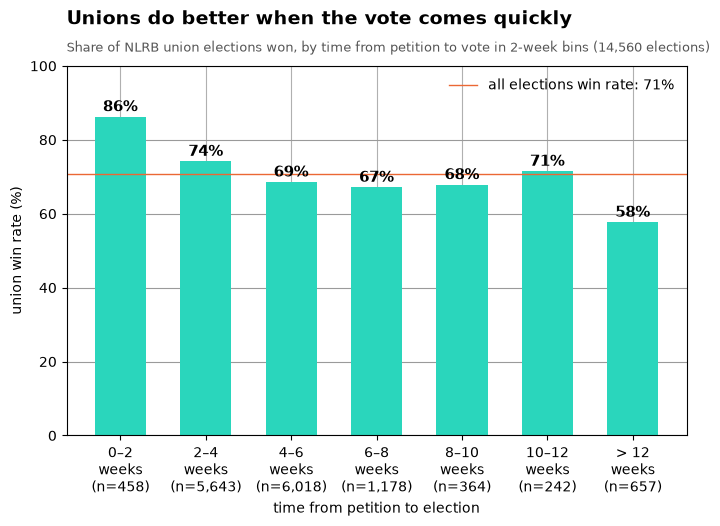

In [297]:
# equal bins of 2 weeks up to 12 weeks; the few longer waits (about 5%) go in one '> 12 weeks' bin
weeks = df['days_petition_to_election'] / 7
wait_bins = list(range(0, 13, 2)) + [600]
wait_labels = [f'{lower}–{lower + 2}\nweeks' for lower in range(0, 12, 2)] + ['> 12\nweeks']
df['wait'] = pd.cut(weeks, wait_bins, labels=wait_labels)
wait_table = df.groupby('wait', observed=True)['union_won'].agg(['mean', 'size'])
print(wait_table.round(3))

tick_labels = [f'{label}\n(n={n:,})' for label, n in zip(wait_table.index, wait_table['size'])]
win_pct = wait_table['mean'] * 100   # average of union_won (1 = won) in each bin
overall_pct = df['union_won'].mean() * 100

plt.figure(figsize=(8,4.8))
plt.bar(tick_labels, win_pct, color=MAIN, width=0.6)
plt.axhline(overall_pct, color=CONTRAST, linewidth=1, label=f'all elections win rate: {overall_pct:.0f}%')
plt.legend(loc='upper right', frameon=False)
for i, pct in enumerate(win_pct):
    plt.text(i, pct + 1.5, f'{pct:.0f}%', ha='center', fontsize=11, fontweight='bold')
plt.ylim(0, 100)
plt.ylabel('union win rate (%)')
plt.xlabel('time from petition to election')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
# bold headline (the message) and a gray subtitle (what is plotted) above the plot
plt.title('Unions do better when the vote comes quickly', loc='left', fontsize=14, fontweight='bold', pad=30)
plt.text(0, 1.03, 'Share of NLRB union elections won, by time from petition to vote in 2-week bins (14,560 elections)',
         transform=plt.gca().transAxes, fontsize=9.5, color='#555555', va='bottom')
plt.savefig('../figures/eda_2_days_win_rate.png', dpi=300, bbox_inches='tight')
plt.show()

### Lawyers and the effect on elections
when the employer has a lawyer the win rate drops from 88% to 72% (for a wait of 4 weeks or less), whether or not the petitioner has one. A longer wait lowers the win rate in every group, by about 6 points, and by 3 points when only the petitioner has a lawyer.

share of elections 4 weeks or less: 0.419
wait_4_weeks     4 weeks or less  more than 4 weeks
who_had_lawyer                                     
neither                     87.5               81.1
employer only               72.1               65.9
petitioner only             86.4               83.3
both                        72.9               66.4
who_had_lawyer
neither            1128
employer only      4875
petitioner only     652
both               7901
dtype: int64


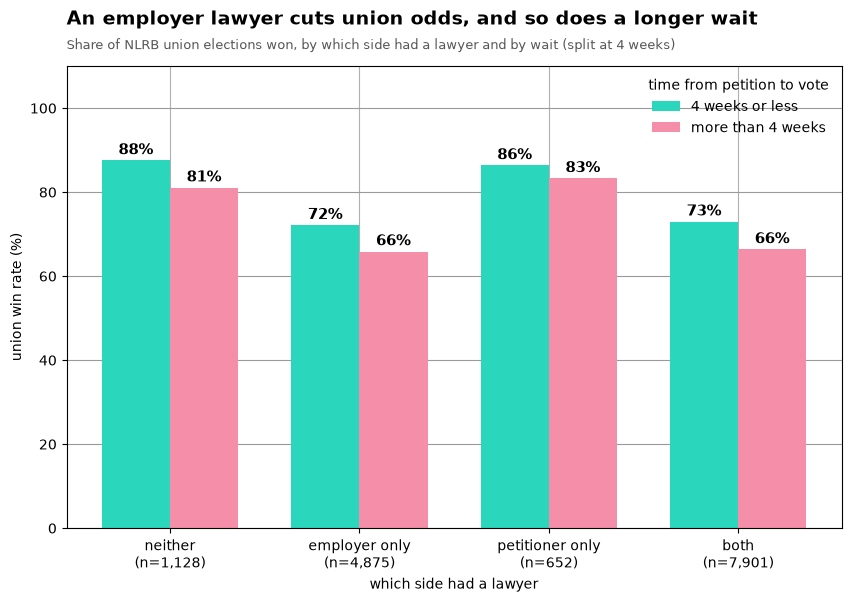

In [ ]:
# same four groups as the exploratory 'which side had a lawyer' plot
combo_names = {(0.0, 0.0): 'neither', (1.0, 0.0): 'employer only',
               (0.0, 1.0): 'petitioner only', (1.0, 1.0): 'both'}
df['who_had_lawyer'] = [combo_names.get((emp, pet)) for emp, pet in zip(df['employer_has_lawyer'], df['petitioner_has_lawyer'])]

# split the wait at 4 weeks (28 days), close to the 31-day median.
# '4 weeks or less' = vote held 28 days or fewer after the petition, 'more than 4 weeks' = 29 days or more
df['wait_4_weeks'] = np.where(df['days_petition_to_election'] <= 28, '4 weeks or less', 'more than 4 weeks')
df.loc[df['days_petition_to_election'].isna(), 'wait_4_weeks'] = np.nan   # no petition date, so no wait
print('share of elections 4 weeks or less:', round((df['wait_4_weeks'] == '4 weeks or less').sum() / df['wait_4_weeks'].notna().sum(), 3))

group_order = ['neither', 'employer only', 'petitioner only', 'both']
lawyer_table = df.groupby(['who_had_lawyer', 'wait_4_weeks'])['union_won'].mean().unstack().loc[group_order] * 100
group_sizes = df.dropna(subset=['wait_4_weeks']).groupby('who_had_lawyer').size().loc[group_order]
print(lawyer_table.round(1))
print(group_sizes)

x = np.arange(len(group_order))
short = lawyer_table['4 weeks or less']
long = lawyer_table['more than 4 weeks']

plt.figure(figsize=(10,6))
plt.bar(x - 0.18, short, width=0.36, color=MAIN, label='4 weeks or less')
plt.bar(x + 0.18, long, width=0.36, color=LIGHT, label='more than 4 weeks')
for i in x:
    plt.text(i - 0.18, short.iloc[i] + 1.5, f'{short.iloc[i]:.0f}%', ha='center', fontsize=11, fontweight='bold')
    plt.text(i + 0.18, long.iloc[i] + 1.5, f'{long.iloc[i]:.0f}%', ha='center', fontsize=11, fontweight='bold')
plt.xticks(x, [f'{name}\n(n={n:,})' for name, n in zip(group_order, group_sizes)])
plt.ylim(0, 110)   # extra room above the bars for the legend
plt.yticks(range(0, 101, 20))
plt.ylabel('union win rate (%)')
plt.xlabel('which side had a lawyer')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
plt.legend(title='time from petition to vote', loc='upper right', frameon=False)
# bold headline (the message) and a gray subtitle (what is plotted) above the plot
plt.title('An employer lawyer cuts union odds, and so does a longer wait', loc='left', fontsize=14, fontweight='bold', pad=30)
plt.text(0, 1.03, 'Share of NLRB union elections won, by which side had a lawyer and by wait (split at 4 weeks)',
         transform=plt.gca().transAxes, fontsize=9.5, color='#555555', va='bottom')
plt.savefig('../figures/eda_3_lawyer_and_speed.png', dpi=300, bbox_inches='tight')
plt.show()

### Union win by unit size
How smaller voting pools also indicated a higher chance of winning

          mean  size
unit                
≤ 5      0.796  1763
6–10     0.763  2241
11–20    0.736  3196
21–50    0.690  3959
51–100   0.646  1958
101–250  0.612  1375
> 250    0.631   621


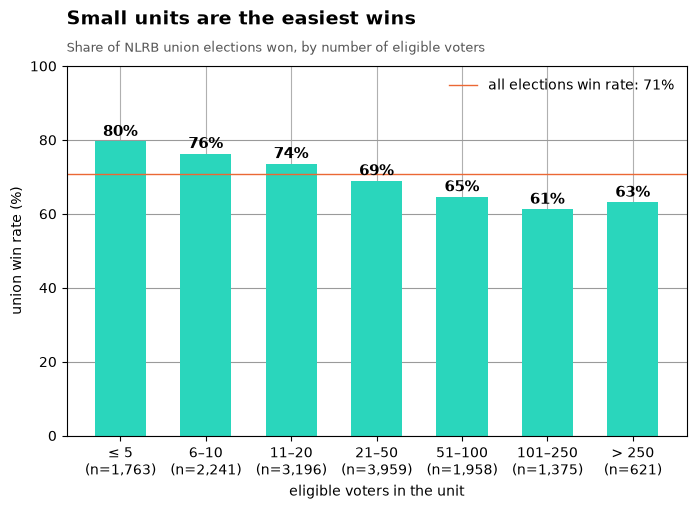

In [296]:
unit_bins = [0, 5, 10, 20, 50, 100, 250, 40000]
unit_labels = ['≤ 5', '6–10', '11–20', '21–50', '51–100', '101–250', '> 250']
df['unit'] = pd.cut(df['eligible'], unit_bins, labels=unit_labels)
unit_table = df.groupby('unit', observed=True)['union_won'].agg(['mean', 'size'])
print(unit_table.round(3))

tick_labels = [f'{label}\n(n={n:,})' for label, n in zip(unit_table.index, unit_table['size'])]
win_pct = unit_table['mean'] * 100

plt.figure(figsize=(8,4.8))
plt.bar(tick_labels, win_pct, color=MAIN, width=0.6)
plt.axhline(overall_pct, color=CONTRAST, linewidth=1, label=f'all elections win rate: {overall_pct:.0f}%')
plt.legend(loc='upper right', frameon=False)
for i, pct in enumerate(win_pct):
    plt.text(i, pct + 1.5, f'{pct:.0f}%', ha='center', fontsize=11, fontweight='bold')
plt.ylim(0, 100)
plt.ylabel('union win rate (%)')
plt.xlabel('eligible voters in the unit')
plt.grid(axis='y', color=GRID)
plt.gca().set_axisbelow(True)   # grid behind the bars
# bold headline (the message) and a gray subtitle (what is plotted) above the plot
plt.title('Small units are the easiest wins', loc='left', fontsize=14, fontweight='bold', pad=30)
plt.text(0, 1.03, 'Share of NLRB union elections won, by number of eligible voters',
         transform=plt.gca().transAxes, fontsize=9.5, color='#555555', va='bottom')
plt.savefig('../figures/eda_4_unit_size.png', dpi=300, bbox_inches='tight')
plt.show()